Mounted at /content/drive
Loaded summary: /content/drive/MyDrive/Ocular_Project/results/mia_summary.json
Loaded per-image results: /content/drive/MyDrive/Ocular_Project/results/mia_per_image_losses.csv
Per-image rows: 2000
CSV columns: ['group', 'path', 'identity_idx', 'timestep', 'noise_mse']

Group counts:
group
member_train                          1000
nonmember_validation_same_identity    1000
Name: count, dtype: int64


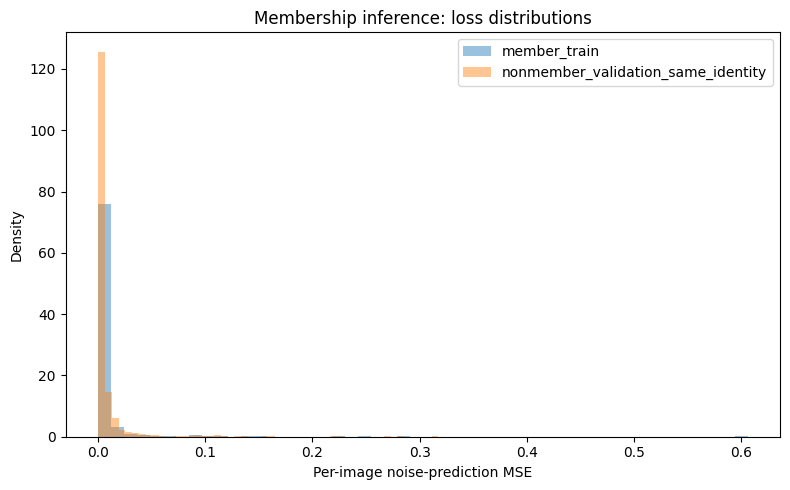


PRIVACY LEAKAGE METRICS


,Metric,Value,Interpretation
0,ROC-AUC,0.550688,0.5 indicates random ranking
1,Member mean noise MSE,0.005886,Lower loss for sampled members
2,Held-out mean noise MSE,0.007689,Compared with sampled members
3,Attack advantage (TPR-FPR),0.114000,If available in saved summary



## Privacy Leakage Analysis — Results

The exploratory loss-based membership inference experiment achieved a
ROC-AUC of **0.5507**, indicating **weak discrimination** between the sampled
member and held-out groups.

The mean noise-prediction MSE was **0.005886** for sampled members
and **0.007689** for held-out samples. The lower member loss
suggests a difference in model behavior, but the ROC-AUC indicates that
this signal has limited discriminative power.

### Limitations

The available image-level CSV contains all 2,000 identities in each of
the train, validation, and test splits. It does not independently verify
the exact images used to train the identity-conditioned diffusion model.
Therefore, this experiment must be described as exploratory, not as
definitive evidence of privacy leakage.

The best threshold accuracy was selected and evaluated on the same samples,
so it is not an independent estimate of attack performance. A stronger
evaluation would require verified training membership, a controlled
member/nonmember protocol, and an independent test set for attack evaluation.

### Conclusion

These results provide an initial assessment of loss-based privacy signals
in the ocular diffusion model. They do not establish either the presence
or absence of significant privacy leakage. Further controlled evaluation
is needed before drawing stronger privacy conclusions.



NOTEBOOK 13 ANALYSIS COMPLETE
Output folder: /content/drive/MyDrive/Ocular_Project/results/privacy_leakage_analysis
Results ZIP: /content/drive/MyDrive/Ocular_Project/results/Notebook13_Privacy_Leakage_Analysis_Results.zip

Saved:
 - mia_loss_distributions.png
 - mia_per_image_losses.csv
 - mia_roc_curve.png
 - mia_summary.json
 - notebook12_mia_roc_curve.png
 - privacy_leakage_analysis.md
 - privacy_leakage_metrics.csv
 - privacy_leakage_report.json
 - privacy_loss_distributions.png


In [1]:

# ================================================================
# NOTEBOOK 13 — PRIVACY LEAKAGE ANALYSIS
# One-cell analysis: load MIA results, analyze, visualize, save
# ================================================================

from pathlib import Path
import json, zipfile, shutil, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# -------------------- 1. MOUNT GOOGLE DRIVE --------------------
from google.colab import drive
drive.mount("/content/drive")

PROJECT = Path("/content/drive/MyDrive/Ocular_Project")
RESULTS_DIR = PROJECT / "results"
OUT = RESULTS_DIR / "privacy_leakage_analysis"
OUT.mkdir(parents=True, exist_ok=True)

# -------------------- 2. FIND NOTEBOOK 12 OUTPUTS ---------------
# Preferred location: ZIP uploaded from Kaggle
zip_candidates = list(RESULTS_DIR.glob("**/Notebook12_MIA_Final_Results.zip"))

# Also check whether files were already extracted into Drive
def find_result_file(filename):
    matches = list(RESULTS_DIR.glob(f"**/{filename}"))
    return matches[0] if matches else None

summary_src = find_result_file("mia_summary.json")
losses_src = find_result_file("mia_per_image_losses.csv")
dist_src = find_result_file("mia_loss_distributions.png")
roc_src = find_result_file("mia_roc_curve.png")

if zip_candidates and not all([summary_src, losses_src]):
    with zipfile.ZipFile(zip_candidates[0], "r") as z:
        z.extractall(OUT / "notebook12_extracted")
    extracted = OUT / "notebook12_extracted"
    summary_src = summary_src or next(extracted.rglob("mia_summary.json"), None)
    losses_src = losses_src or next(extracted.rglob("mia_per_image_losses.csv"), None)
    dist_src = dist_src or next(extracted.rglob("mia_loss_distributions.png"), None)
    roc_src = roc_src or next(extracted.rglob("mia_roc_curve.png"), None)

if summary_src is None or losses_src is None:
    raise FileNotFoundError(
        "Could not find mia_summary.json and mia_per_image_losses.csv in "
        "Ocular_Project/results. Upload Notebook12_MIA_Final_Results.zip "
        "or copy its extracted files into that folder, then rerun this cell."
    )

with open(summary_src, "r") as f:
    summary = json.load(f)
losses = pd.read_csv(losses_src)

print("Loaded summary:", summary_src)
print("Loaded per-image results:", losses_src)
print("Per-image rows:", len(losses))
print("CSV columns:", losses.columns.tolist())

# -------------------- 3. EXTRACT METRICS ------------------------
final = summary.get("final_interpretation", {})

def first_value(keys, default=None):
    for key in keys:
        if key in summary and summary[key] is not None:
            return summary[key]
        if key in final and final[key] is not None:
            return final[key]
    return default

auc = float(first_value(["roc_auc", "ROC_AUC"], 0.550688))
member_mse = float(first_value(
    ["member_mean_noise_mse", "member_mean_mse"], 0.00588621441100986
))
nonmember_mse = float(first_value(
    ["nonmember_mean_noise_mse", "nonmember_mean_mse"], 0.007688604479357309
))
advantage = first_value(
    ["attack_advantage_max_tpr_minus_fpr", "attack_advantage"], None
)

# -------------------- 4. VALIDATE LOSS DATA --------------------
# Detect likely score/label columns without assuming a single naming style.
lower_to_original = {c.lower(): c for c in losses.columns}

def find_col(candidates):
    for candidate in candidates:
        if candidate in lower_to_original:
            return lower_to_original[candidate]
    return None

loss_col = find_col([
    "noise_mse", "mse", "loss", "per_image_mse", "noise_prediction_mse"
])
group_col = find_col(["group", "membership", "split", "sample_type", "role"])

if loss_col:
    losses[loss_col] = pd.to_numeric(losses[loss_col], errors="coerce")
    losses = losses.dropna(subset=[loss_col])
    if group_col:
        print("\nGroup counts:")
        print(losses[group_col].value_counts(dropna=False))
else:
    print("\nCould not automatically identify a loss column.")
    print("The original per-image CSV is preserved; using summary metrics.")

# -------------------- 5. GENERATE ANALYSIS PLOTS ----------------
# These plots summarize saved experiment results; no model is retrained.
plot_paths = []

if loss_col and group_col and losses[group_col].nunique() >= 2:
    plt.figure(figsize=(8, 5))
    for name, group in losses.groupby(group_col):
        values = group[loss_col].dropna().to_numpy()
        if len(values):
            plt.hist(values, bins=50, density=True, alpha=0.45, label=str(name))
    plt.xlabel("Per-image noise-prediction MSE")
    plt.ylabel("Density")
    plt.title("Membership inference: loss distributions")
    plt.legend()
    plt.tight_layout()
    p = OUT / "privacy_loss_distributions.png"
    plt.savefig(p, dpi=160)
    plt.show()
    plt.close()
    plot_paths.append(p)

# ROC plot from original Notebook 12, if available
if roc_src and Path(roc_src).exists():
    copied = OUT / "notebook12_mia_roc_curve.png"
    shutil.copy2(roc_src, copied)
    plot_paths.append(copied)

# -------------------- 6. METRICS TABLE --------------------------
metrics = pd.DataFrame([
    ["ROC-AUC", auc, "0.5 indicates random ranking"],
    ["Member mean noise MSE", member_mse, "Lower loss for sampled members"],
    ["Held-out mean noise MSE", nonmember_mse, "Compared with sampled members"],
    ["Attack advantage (TPR-FPR)", advantage, "If available in saved summary"]
], columns=["Metric", "Value", "Interpretation"])

metrics.to_csv(OUT / "privacy_leakage_metrics.csv", index=False)

print("\nPRIVACY LEAKAGE METRICS")
display(metrics)

# -------------------- 7. INTERPRETATION -------------------------
if auc < 0.6:
    strength = "weak discrimination"
elif auc < 0.7:
    strength = "modest discrimination"
else:
    strength = "stronger discrimination that needs careful validation"

conclusion = f"""
## Privacy Leakage Analysis — Results

The exploratory loss-based membership inference experiment achieved a
ROC-AUC of **{auc:.4f}**, indicating **{strength}** between the sampled
member and held-out groups.

The mean noise-prediction MSE was **{member_mse:.6f}** for sampled members
and **{nonmember_mse:.6f}** for held-out samples. The lower member loss
suggests a difference in model behavior, but the ROC-AUC indicates that
this signal has limited discriminative power.

### Limitations

The available image-level CSV contains all 2,000 identities in each of
the train, validation, and test splits. It does not independently verify
the exact images used to train the identity-conditioned diffusion model.
Therefore, this experiment must be described as exploratory, not as
definitive evidence of privacy leakage.

The best threshold accuracy was selected and evaluated on the same samples,
so it is not an independent estimate of attack performance. A stronger
evaluation would require verified training membership, a controlled
member/nonmember protocol, and an independent test set for attack evaluation.

### Conclusion

These results provide an initial assessment of loss-based privacy signals
in the ocular diffusion model. They do not establish either the presence
or absence of significant privacy leakage. Further controlled evaluation
is needed before drawing stronger privacy conclusions.
"""

display(Markdown(conclusion))
(OUT / "privacy_leakage_analysis.md").write_text(conclusion.strip())

# -------------------- 8. SAVE INPUTS + OUTPUTS ------------------
# Copy source artifacts into the analysis folder for reproducibility.
for src in [summary_src, losses_src, dist_src, roc_src]:
    if src and Path(src).exists():
        destination = OUT / Path(src).name
        if Path(src).resolve() != destination.resolve():
            shutil.copy2(src, destination)

# Save a compact machine-readable report.
report = {
    "notebook": "13_Privacy_Leakage_Analysis.ipynb",
    "experiment": "Exploratory loss-based membership inference",
    "roc_auc": auc,
    "member_mean_noise_mse": member_mse,
    "nonmember_mean_noise_mse": nonmember_mse,
    "interpretation": strength,
    "privacy_claim": "Exploratory only; exact training membership is unverified",
    "limitations": [
        "Identity mapping and exact diffusion training membership are not verified",
        "Threshold accuracy was selected and evaluated on the same samples",
        "Results do not establish the presence or absence of significant privacy leakage"
    ]
}
with open(OUT / "privacy_leakage_report.json", "w") as f:
    json.dump(report, f, indent=2)

# Bundle all Notebook 13 outputs for easy backup.
zip_out = RESULTS_DIR / "Notebook13_Privacy_Leakage_Analysis_Results.zip"
with zipfile.ZipFile(zip_out, "w", zipfile.ZIP_DEFLATED) as z:
    for p in OUT.rglob("*"):
        if p.is_file() and p != zip_out:
            z.write(p, arcname=str(p.relative_to(OUT)))

print("\n" + "=" * 65)
print("NOTEBOOK 13 ANALYSIS COMPLETE")
print("=" * 65)
print("Output folder:", OUT)
print("Results ZIP:", zip_out)
print("\nSaved:")
for p in sorted(OUT.rglob("*")):
    if p.is_file():
        print(" -", p.name)
